# Data quality: evidence

In this notebook I compute again the main results of the report `docs/data_quality/data_quality.pdf`. I start from what each phase saved when it ran on the **full data** of the lake (caches in `data/02_intermediate/quality/` and reports in `docs/dq_reports/`). Each section shows the code and the number it gives.

- I read no player rows: the caches only hold counts, sums and statistics.
- Sections 5 and 7 can also query S3 directly; they need an AWS session and `RUN_S3 = True`.
- To build the caches again from zero: `make layers`, `make validate-gx`, `make reconcile` and `make distributions` (see `GUIA_GREAT_EXPECTATIONS.md`).

In [15]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path.insert(0, str(ROOT / "src" / "quality"))
sys.path.insert(0, str(ROOT / "src" / "features"))
CACHE = ROOT / "data/02_intermediate/quality"
REPORTS = ROOT / "docs/dq_reports"
RUN_S3 = False          # True: sections 5 and 7 query S3 with the SSO session
pd.set_option("display.max_colwidth", 80)

SUMS = re.compile(r"\S+ ([-\d,.]+), \S+ ([-\d,.]+)")


def cached_rows(check: str) -> pd.DataFrame:
    """Rows saved by reconcile.py for one check: one per day and checked item."""
    rows = []
    for f in sorted((CACHE / "reconcile" / check).glob("*.json")):
        rows += json.loads(f.read_text())["rows"]
    return pd.DataFrame(rows)


def sums(extra: str) -> tuple[float, float]:
    """The two sums (source, target) in the detail text of a totals check."""
    a, b = SUMS.search(extra).groups()
    return float(a.replace(",", "")), float(b.replace(",", ""))

## 1. What is in the lake

Inventory from `layers.py`: only file listings and Parquet footers, no data read.

In [16]:
inventory = []
for f in sorted(REPORTS.glob("layer_inventory*.json")):
    for t in json.loads(f.read_text()):
        if t.get("n_files"):
            inventory.append({"layer": t["layer"], "table": t["table"], "first_day": t.get("first_day"),
                              "last_day": t.get("last_day"), "rows": t.get("n_rows"), "days_without_files": t.get("missing_days")})
inventory = pd.DataFrame(inventory)
print(inventory.groupby("layer").agg(tables=("table", "size"), rows=("rows", "sum"), first_day=("first_day", "min"), last_day=("last_day", "max")))
inventory[inventory["layer"] != "org/40-gold"]

                tables        rows   first_day    last_day
layer                                                     
org/10-landing      10  2568045504  2026-06-11  2026-10-15
org/20-bronze        1  8330447064  2025-04-01  2026-05-31
org/40-gold         29  3878736136  2025-04-01  2026-10-14


,layer,table,first_day,last_day,rows,days_without_files
0,org/20-bronze,transactions,2025-04-01,2026-05-31,8330447064,0
30,org/10-landing,kafka-sink/primus/whizdomai-bonus-plan,2026-06-12,2026-10-14,10734,2
31,org/10-landing,kafka-sink/primus/whizdomai-bonuses,2026-06-11,2026-10-15,7233657,0
32,org/10-landing,kafka-sink/primus/whizdomai-payments,2026-06-11,2026-10-15,9506193,0
33,org/10-landing,kafka-sink/primus/whizdomai-players,2026-06-18,2026-10-15,1431725,0
34,org/10-landing,kafka-sink/primus/whizdomai-transactions,2026-06-18,2026-10-15,1605977445,0
35,org/10-landing,kafka-sink/secundus/whizdomai-bonus-plan,2026-06-12,2026-10-14,4558,5
36,org/10-landing,kafka-sink/secundus/whizdomai-bonuses,2026-06-11,2026-10-15,5436936,0
37,org/10-landing,kafka-sink/secundus/whizdomai-payments,2026-06-11,2026-10-15,5729393,0
38,org/10-landing,kafka-sink/secundus/whizdomai-players,2026-06-18,2026-10-15,1547568,0


**Reading:** silver has no table with files; bronze only has `transactions` and ends on 2026-05-31; landing starts in June. From 1 to 17 June there are no raw transactions in any layer.

## 2. Phase 1: validation with Great Expectations

Result saved by `validate.py` for each table and day (rules: grain, nulls, ranges, non negative, batch day and schema).

In [17]:
items = [json.loads(f.read_text()) for f in (CACHE / "gx").rglob("*.json")]
checks = pd.DataFrame([{"table": i["table"], "day": i["day"], "rows": i["n_rows"], **r} for i in items for r in i["rows"]])
by_table = checks.groupby("table").agg(days=("day", "nunique"), rules=("rule", "size"),
                                       failed=("success", lambda s: int((~s).sum())))
grain = checks[checks["rule"] == "grain"].groupby("table")["success"].all().rename("grain_unique")
print(f"{checks['table'].nunique()} tables, {checks.drop_duplicates(['table', 'day'])['rows'].sum():,} rows validated")
by_table.join(grain).sort_values("failed", ascending=False).head(10)

30 tables, 118,362,814 rows validated


,days,rules,failed,grain_unique
table,,,,
gld_player_signals_daily,6,270,27,True
gld_player_gaming_daily,3,72,8,True
gld_player_lifetime,3,24,3,True
gld_players,3,33,3,True
gld_brand,3,27,0,True
gld_brand_cohorts_daily,3,24,0,True
gld_brand_segments_movements,3,21,0,True
gld_brand_signals_daily,3,66,0,True
gld_brand_signals_hourly,3,24,0,True


In [18]:
# Data problems: rules that fail in a few rows (not contract errors)
failed = checks[~checks["success"] & checks["rule"].isin(["not_null", "non_negative"])]
failed.groupby(["table", "rule", "column"]).agg(days=("day", "nunique"), rows=("unexpected_count", "sum"),
                                                 max_pct=("unexpected_percent", "max"), min_value=("min", "min"))

days     rows  \
table                    rule         column                                  
gld_player_gaming_daily  non_negative won_playable_bonus         2        2   
                                      won_playable_bonus_eur     2        2   
                                      won_released_bonus         2       11   
                                      won_released_bonus_eur     2       11   
gld_player_lifetime      not_null     brand_id                   3  1902880   
gld_player_signals_daily non_negative won_eur_l180d              6       95   
                                      won_eur_l30d               2        3   
                                      won_eur_l7d                2        3   
                                      won_eur_l90d               6       39   
                                      won_eur_today              2        3   
gld_players              not_null     brand_id                   3  1894601   

                                                                max_pct  \
table                    rule         column                              
gld_player_gaming_daily  non_negative won_playable_bonus       0.000906   
                                      won_playable_bonus_eur   0.000906   
                                      won_released_bonus       0.008568   
                                      won_released_bonus_eur   0.008568   
gld_player_lifetime      not_null     brand_id                30.736900   
gld_player_signals_daily non_negative won_eur_l180d            0.000981   
                                      won_eur_l30d             0.000115   
                                      won_eur_l7d              0.000115   
                                      won_eur_l90d             0.000404   
                                      won_eur_today            0.000115   
gld_players              not_null     brand_id                16.178188   

                                                              min_value  
table                    rule         column                             
gld_player_gaming_daily  non_negative won_playable_bonus        -1.6700  
                                      won_playable_bonus_eur    -0.0302  
                                      won_released_bonus     -9000.0000  
                                      won_released_bonus_eur  -163.0300  
gld_player_lifetime      not_null     brand_id                      NaN  
gld_player_signals_daily non_negative won_eur_l180d           -176.0000  
                                      won_eur_l30d             -35.8383  
                                      won_eur_l7d              -35.8383  
                                      won_eur_l90d             -42.0312  
                                      won_eur_today            -36.3841  
gld_players              not_null     brand_id                      NaN

## 3. Kafka files in landing: duplicates and losses

The Kafka to S3 connector names each file `<topic>+<partition>+<first offset>`. With the number of rows of each file (from the Parquet footer), each file must start where the previous one ends. A gap means lost messages; an overlap means messages written twice.

In [19]:
continuity = []
for f in sorted((CACHE / "footers/org_10-landing").glob("*.parquet")):
    d = pd.read_parquet(f, columns=["path", "n_rows"])
    name = d["path"].str.rsplit("/", n=1).str[-1].str.extract(r"\+(\d+)\+(\d+)\.")
    d["partition"], d["first"] = name[0].astype(int), name[1].astype(int)
    d["day"] = d["path"].str.extract(r"/(\d{4}/\d{2}/\d{2})/")[0]
    d = d.sort_values(["partition", "first"])
    d["step"] = d["first"] - (d["first"] + d["n_rows"]).groupby(d["partition"]).shift()
    for _, r in d[d["step"].notna() & (d["step"] != 0)].iterrows():
        continuity.append({"table": f.stem.replace("kafka-sink__", ""), "day": r["day"],
                           "kind": "gap (lost)" if r["step"] > 0 else "overlap (twice)", "offsets": abs(int(r["step"]))})
continuity = pd.DataFrame(continuity)
summary = continuity[~continuity["table"].str.contains("players")].groupby(["day", "table", "kind"])["offsets"].sum()
summary.reset_index().pivot_table(index=["day", "table"], columns="kind", values="offsets", fill_value=0)

kind                                         gap (lost)  overlap (twice)
day        table                                                        
2026/07/16 primus__whizdomai-bonus-plan             0.0             26.0
           primus__whizdomai-bonuses                0.0          12805.0
           primus__whizdomai-payments               0.0           9841.0
           primus__whizdomai-transactions           0.0         468345.0
           secundus__whizdomai-bonuses              0.0          26274.0
           secundus__whizdomai-payments             0.0          18683.0
           secundus__whizdomai-transactions         0.0         479766.0
2026/08/04 secundus__whizdomai-transactions         0.0         199998.0
2026/09/03 secundus__whizdomai-transactions     67876.0              0.0
2026/09/11 secundus__whizdomai-transactions     72180.0              0.0

**Reading:** on 16 July and 4 August about 1.1 million transactions were written twice; on 3 and 11 September about 140,000 transactions of `secundus` were lost. (I leave `players` out: its small gaps fit a compacted topic.)

## 4. Landing against gold: bets per day (1 to 12 October)

Check `landing_to_gaming_by_day` of `reconcile.py`: bets (`GAME_BET`) in landing per event day, against `bets` in `gld_player_gaming_daily`.

Total: gold +0.47% over landing


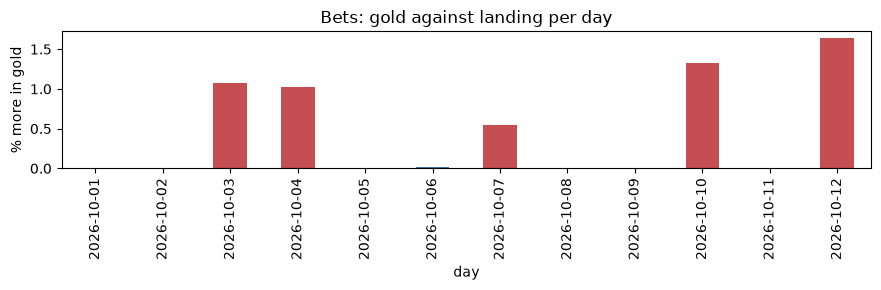

,landing,gold,difference_pct
day,,,
2026-10-01,19182827.0,19182931.0,0.001
2026-10-02,19855637.0,19856558.0,0.005
2026-10-03,20096129.0,20313050.0,1.079
2026-10-04,18345690.0,18532651.0,1.019
2026-10-05,19734256.0,19735116.0,0.004
2026-10-06,19270415.0,19272601.0,0.011
2026-10-07,19135591.0,19240981.0,0.551
2026-10-08,18962049.0,18962984.0,0.005
2026-10-09,20150856.0,20152718.0,0.009


In [20]:
r = cached_rows("totals_landing_to_gaming_by_day")
bets = r[(r["item"] == "bets differs") & r["day"].str.startswith("2026-10")].copy()
bets[["landing", "gold"]] = bets["extra"].apply(lambda e: pd.Series(sums(e)))
bets["difference_pct"] = 100 * (bets["gold"] - bets["landing"]) / bets["landing"]
bets = bets.set_index("day")[["landing", "gold", "difference_pct"]]
print(f"Total: gold {100 * (bets.gold.sum() - bets.landing.sum()) / bets.landing.sum():+.2f}% over landing")
ax = bets["difference_pct"].plot.bar(figsize=(9, 3), color=["#C44E52" if v > 0.1 else "#4C72B0" for v in bets["difference_pct"]])
ax.set_ylabel("% more in gold"); ax.set_title("Bets: gold against landing per day"); plt.tight_layout(); plt.show()
bets.round(3)

**Reading:** 7 days match (0.01% or less); on 5 days gold has between 0.55% and 1.64% more. The landing files of October are continuous (section 3), so landing has all the messages: the extra is in gold.

## 5. Per hour: windows that gold counts twice

Ratio between the hourly turnover in gold (`gld_brand_signals_hourly`, in EUR) and the amount wagered in landing (original currency), per brand and hour. Inside one brand and one day this ratio is the exchange rate, so it should be flat. This section needs S3.

In [21]:
if RUN_S3:
    from datalake import BUCKET, s3_duckdb
    con = s3_duckdb(); con.sql("SET TimeZone = 'UTC'")
    org = f"s3://{BUCKET}/org"
    out = []
    for day in ("2026/10/09", "2026/10/10"):
        d = day.replace("/", "-")
        landing = " UNION ALL ".join(
            f"SELECT brandId, dateTime, tranType, amountReal, amountReleasedBonus, amountPlayableBonus "
            f"FROM read_parquet('{org}/10-landing/kafka-sink/{op}/whizdomai-transactions/{day}/*.parquet')"
            for op in ("primus", "secundus"))
        out.append(con.sql(f"""
            WITH l AS (SELECT brandId AS brand_id, date_trunc('hour', dateTime) AS hour,
                              sum(abs(amountReal) + abs(amountReleasedBonus) + abs(amountPlayableBonus)) AS wagered
                       FROM ({landing}) WHERE tranType = 'GAME_BET' AND CAST(dateTime AS DATE) = DATE '{d}' GROUP BY ALL),
                 map AS (SELECT DISTINCT tenant_id, brand_id FROM read_parquet('{org}/40-gold/gld_player_gaming_daily/{day}/*.parquet')),
                 g AS (SELECT m.brand_id, h.event_hour AS hour, sum(h.turnover_eur) AS turnover_eur
                       FROM read_parquet('{org}/40-gold/gld_brand_signals_hourly/{day}/*.parquet') h JOIN map m USING (tenant_id)
                       WHERE CAST(h.event_hour AS DATE) = DATE '{d}' GROUP BY ALL),
                 r AS (SELECT brand_id, hour, turnover_eur / nullif(wagered, 0) AS ratio FROM l JOIN g USING (brand_id, hour)),
                 n AS (SELECT *, ratio / median(ratio) OVER (PARTITION BY brand_id) AS rel FROM r)
            SELECT '{d}' AS day, hour(hour) AS hour_utc, round(median(rel), 4) AS median_rel,
                   count(*) FILTER (WHERE rel > 1.02) AS brands_over_2pct
            FROM n GROUP BY ALL ORDER BY hour_utc""").df())
    hourly = pd.concat(out)
    display(hourly[hourly["median_rel"] > 1.05])
else:
    print("RUN_S3 = False. Result of my last run (2026-10-15):")
    print(pd.DataFrame({"day": ["2026-10-09", "2026-10-09", "2026-10-10", "2026-10-10"], "hour_utc": [16, 21, 22, 23],
                        "median_rel": [1.1743, 1.1834, 1.1675, 1.1727], "brands_over_2pct": [20, 19, 19, 20]}))

RUN_S3 = False. Result of my last run (2026-10-15):
          day  hour_utc  median_rel  brands_over_2pct
0  2026-10-09        16      1.1743                20
1  2026-10-09        21      1.1834                19
2  2026-10-10        22      1.1675                19
3  2026-10-10        23      1.1727                20


**Reading:** the ratio is 1.000 in every hour except two per day, where it goes up 17% in all brands at the same time: about 10 minutes counted twice. Two hours at +17% are 2/24 × 17% ≈ 1.4% of the day, which is the extra of 10 October in section 4.

## 6. Payments: landing against the two gold tables (1 to 12 October)

In [22]:
pay = []
for check, table in (("period_totals_landing_payments_to_gold", "gld_player_payments"),
                     ("period_totals_landing_payments_to_daily", "gld_player_payments_daily")):
    r = cached_rows(check)
    for _, x in r[r["item"].str.endswith("differs")].iterrows():
        a, b = sums(x["extra"])
        pay.append({"gold_table": table, "measure": x["item"].replace(" differs", ""), "landing": a, "gold": b,
                    "difference_pct": round(100 * (b - a) / a, 3)})
pd.DataFrame(pay)

,gold_table,measure,landing,gold,difference_pct
0,gld_player_payments,deposits,5.027920e+05,5.027930e+05,0.000
1,gld_player_payments,withdrawals,6.316500e+04,6.315300e+04,-0.019
2,gld_player_payments,deposit_amount,1.968235e+09,1.968234e+09,-0.000
3,gld_player_payments,withdrawal_amount,1.322482e+09,1.315888e+09,-0.499
4,gld_player_payments_daily,deposit_count,5.027920e+05,5.040620e+05,0.253
5,gld_player_payments_daily,withdraw_count,6.316500e+04,6.315600e+04,-0.014
6,gld_player_payments_daily,deposit_amount,1.968235e+09,1.969896e+09,0.084
7,gld_player_payments_daily,withdraw_amount,1.322482e+09,1.315891e+09,-0.498


**Reading:** landing and `gld_player_payments` match (502,792 against 502,793 completed deposits); `gld_player_payments_daily` has 0.25% more deposits than the source. Withdrawals lose 0.5% of the amount in gold.

## 7. Bronze against gold: the amount wagered is summed in absolute value (29 to 31 May)

In [23]:
# Bronze against gold with the current rule (absolute value), 3 days, from the cache
r = cached_rows("totals_bronze_to_gaming")
rows = []
for m in ("bets", "wins", "wagered_real", "won_real"):
    a, b = map(sum, zip(*r[r["item"] == f"{m} differs"]["extra"].map(sums)))
    rows.append({"measure": m, "bronze": a, "gold": b, "difference_pct": round(100 * (b - a) / a, 4)})
pd.DataFrame(rows)

,measure,bronze,gold,difference_pct
0,bets,4.846462e+07,4.846464e+07,0.0000
1,wins,1.137947e+07,1.138000e+07,0.0046
2,wagered_real,2.477483e+09,2.477519e+09,0.0015
3,won_real,2.368165e+09,2.365038e+09,-0.1321


In [24]:
# With sign against absolute value, one day (2026-05-31), straight from S3
if RUN_S3:
    from datalake import BUCKET, s3_duckdb
    con = s3_duckdb(); org = f"s3://{BUCKET}/org"
    src = f"read_parquet('{org}/20-bronze/transactions/2026/05/31/*.parquet')"
    print(con.sql(f"""
        SELECT (SELECT -sum(amount_real) FROM {src} WHERE tran_type = 'GAME_BET') AS bronze_with_sign,
               (SELECT sum(abs(amount_real)) FROM {src} WHERE tran_type = 'GAME_BET') AS bronze_absolute,
               (SELECT sum(wagered_real) FROM read_parquet('{org}/40-gold/gld_player_gaming_daily/2026/05/31/*.parquet')) AS gold
    """).df())
else:
    print("RUN_S3 = False. Result of my first run (2026-05-31, original currency):")
    print(pd.DataFrame({"bronze_with_sign": [852_398_951.04], "bronze_absolute": [856_756_003.84],
                        "gold": [856_759_974.12]}))

RUN_S3 = False. Result of my first run (2026-05-31, original currency):
   bronze_with_sign  bronze_absolute          gold
0      8.523990e+08     8.567560e+08  8.567600e+08


**Reading:** the number of bets matches (17 out of 48.5 million). The amount wagered matches in absolute value (0.0015%); with sign, bronze is 0.5% below gold. So gold counts the `GAME_BET` rows with a positive amount (refunds or adjustments) as wagered, instead of taking them away. The amount won differs by 0.13%.

## 8. `signals_daily` has extra rows (April 2025 to October 2026)

Total: 1,029,248 rows; June and July 2026: 81%


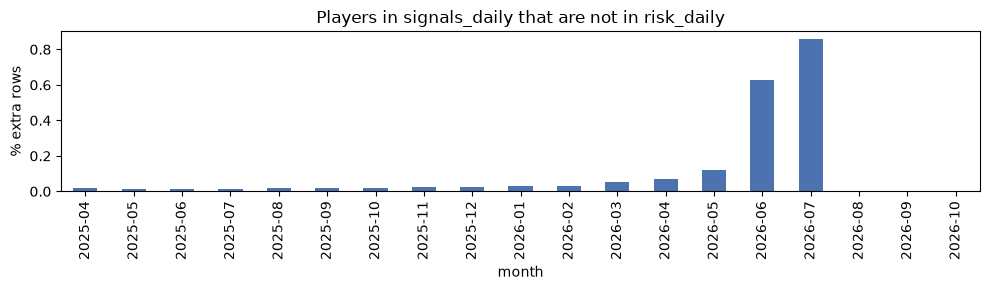

In [25]:
r = cached_rows("same_keys_player_daily")
extra = r[r["item"].str.startswith("keys only in gld_player_signals_daily (not in gld_player_risk_daily")].copy()
extra["month"] = extra["day"].str[:7]
monthly = extra.groupby("month").agg(extra_rows=("problems", "sum"), rows=("n", "sum"))
monthly["pct"] = 100 * monthly["extra_rows"] / monthly["rows"]
print(f"Total: {int(monthly['extra_rows'].sum()):,} rows; June and July 2026: "
      f"{monthly.loc[['2026-06', '2026-07'], 'extra_rows'].sum() / monthly['extra_rows'].sum():.0%}")
ax = monthly["pct"].plot.bar(figsize=(10, 3), color="#4C72B0"); ax.set_ylabel("% extra rows")
ax.set_title("Players in signals_daily that are not in risk_daily"); plt.tight_layout(); plt.show()

## 9. Phase 3: distributions and PSI bins (September 2026)

Statistics of the 527 gold metrics computed by `distributions.py`, and their type with the rules of `configs/quality.yaml`.

In [26]:
import yaml
import distributions

cfg = yaml.safe_load((ROOT / "configs/quality.yaml").read_text())["distributions"]
stats = []
for f in sorted((CACHE / "distributions").glob("*_2026-09-01_2026-09-30.json")):
    table = f.name.replace("_2026-09-01_2026-09-30.json", "")
    for s in json.loads(f.read_text())["stats"]:
        s.setdefault("p99_nonzero", None)
        stats.append({"table": table, **s, **distributions.classify(s, cfg)})
stats = pd.DataFrame(stats)
lost = stats[(stats["decile_bins"] < 10) & ~stats["type"].isin(["few_values", "empty"])]
print(f"{len(stats)} metrics; plain deciles (as in alerts.psi) keep fewer than 10 bins in {len(lost)} ({len(lost) / len(stats):.0%})")
stats["type"].value_counts()

527 metrics; plain deciles (as in alerts.psi) keep fewer than 10 bins in 401 (76%)


type
zero_inflated    267
heavy_tail        95
signed            63
skewed            52
symmetric         27
few_values        23
Name: count, dtype: int64

In [27]:
# A real example: the decile edges of a metric with many zeros, and the bins that are left
ex = stats[(stats["table"] == "gld_player_signals_daily") & (stats["metric"] == "deposits_eur_today")].iloc[0]
print("decile edges:", [round(x, 2) for x in ex["deciles"]])
print("bins left (np.unique of the edges):", ex["decile_bins"], "of 10;  zeros:", f"{ex['zero_share']:.0%}")

decile edges: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 13211.18]
bins left (np.unique of the edges): 1 of 10;  zeros: 99%


In [28]:
# Impossible values: the maximum against the 99th percentile
cols = ["table", "metric", "p99", "max"]
stats[stats["metric"].isin(["play_secs_today", "value_decline", "wager_requirement", "rtp_actual", "pct_change"])][cols]

,table,metric,p99,max
117,gld_brand_top_movers_daily,pct_change,23.280443,3.233319e+06
194,gld_player_bonuses,wager_requirement,190937.448576,3.000000e+18
204,gld_player_engagement_daily,play_secs_today,291.780588,2.638989e+07
267,gld_player_gaming_daily,rtp_actual,5.200037,4.911410e+05
330,gld_player_risk_daily,value_decline,100.017274,5.726838e+07
426,gld_player_signals_daily,play_secs_today,260.979573,2.638989e+07
466,gld_player_signals_daily,value_decline,100.153578,5.726838e+07


## 10. Summary

| Finding | Section | Evidence |
|---|---|---|
| Gold counts some windows of about 10 minutes twice | 4 and 5 | +0.55% to +1.64% on 5 days; +17% in two hours per day |
| Kafka connector: duplicates and losses | 3 | 16 Jul and 4 Aug (written twice); 3 and 11 Sep (lost) |
| `gld_player_payments_daily` has more deposits than the source | 6 | +0.25% |
| `signals_daily` has extra rows | 8 | 1 million, 81% of them in June and July 2026 |
| The amount wagered includes positive amounts | 7 | it matches only in absolute value |
| Empty `brand_id`, impossible values | 2 and 9 | 100% of `signals_daily`; 305 days of play in one day |
| PSI with few bins | 9 | 76% of the metrics |